# interpies_lite 示例

本 notebook 演示新写的轻量位场处理包 `interpies_lite` 的核心流程：

1. 构造合成网格（模拟重磁异常）
2. 查看元数据与成图
3. 去趋势 + 平滑预处理
4. 计算方向导数与垂直导数
5. 边界识别算子（HGM / Tilt / 总梯度 / TAHG）
6. 向上延拓与区域-局部分离
7. 一次性对比图

所有变换均返回新的 `Grid` 对象，支持链式调用。


## 1. 导入包并构造合成数据

In [3]:
import sys
from pathlib import Path
# 自动定位 interpies_lite 包（向上查找直到找到）
_p = Path.cwd()
for _ in [_p, *(_p.parents)]:
    if (_ / 'interpies_lite').exists():
        sys.path.insert(0, str(_))
        break

import numpy as np
import matplotlib.pyplot as plt
import interpies_lite as ip

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
# 构造一个 200x200 的合成网格：两个高斯异常 + 线性趋势 + 噪声
n = 200
x = np.linspace(-10000, 10000, n)
y = np.linspace(-10000, 10000, n)
XX, YY = np.meshgrid(x, y)

# 正异常（高磁/高密度体）
g1 = 100 * np.exp(-((XX - 3000)**2 + (YY - 2000)**2) / (2 * 1500**2))
# 负异常
g2 = -60 * np.exp(-((XX + 4000)**2 + (YY + 3000)**2) / (2 * 2000**2))
# 线性区域趋势
trend = 0.0015 * XX + 0.0008 * YY
# 噪声
rng = np.random.default_rng(42)
noise = rng.normal(0, 0.8, size=XX.shape)

data = g1 + g2 + trend + noise

# 包装为 Grid（假设 UTM 投影，像元 100 m）
grid = ip.Grid.from_array(
    data,
    west=0, north=20000,
    cellsize=100,
    crs="EPSG:32633",
    name="synthetic_anomaly",
)
print("构造完成：", grid.nrows, "行 x", grid.ncols, "列")


构造完成： 200 行 x 200 列


## 2. 查看元数据并成图

Grid: synthetic_anomaly
  file      : Unknown
  shape     : 200 rows x 200 cols
  cellsize  : 100.0 x 100.0
  extent    : [0.0, 20000.0, 0.0, 20000.0]
  crs       : EPSG:32633
  min/max   : -69.682 / 107.333
  mean/std  : -0.224 +/- 22.123


<Axes: title={'center': '原始合成异常（含趋势与噪声）'}, xlabel='Easting', ylabel='Northing'>

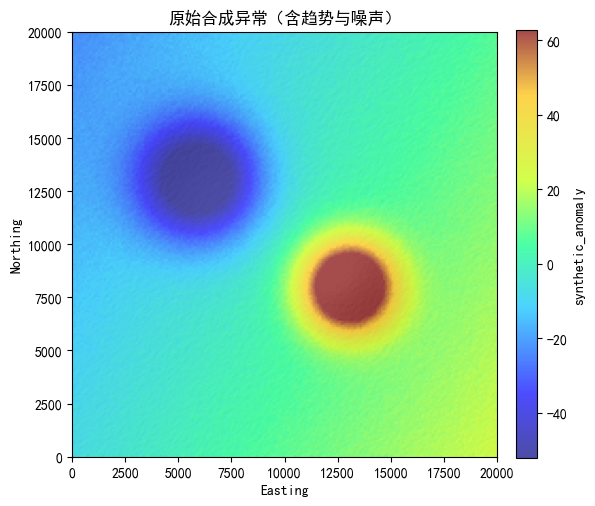

In [4]:
grid.info()
grid.show(title="原始合成异常（含趋势与噪声）", figsize=(6, 6))


## 3. 预处理：去趋势 + 平滑

- `detrend(degree=1)`：用一次多项式拟合区域趋势面并扣除
- `smooth(win=5)`：Savitzky-Golay 平滑，压制随机噪声


<Axes: title={'center': '去趋势 + 平滑后'}, xlabel='Easting', ylabel='Northing'>

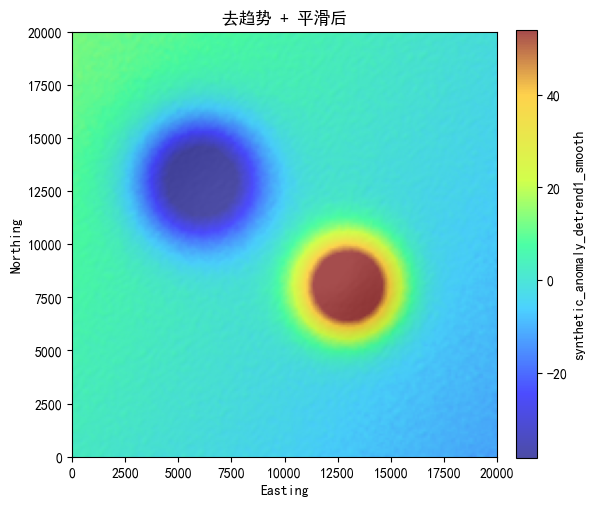

In [5]:
clean = grid.detrend(degree=1).smooth(deg=3, win=5)
clean.show(title="去趋势 + 平滑后", figsize=(6, 6))


## 4. 方向导数与垂直导数

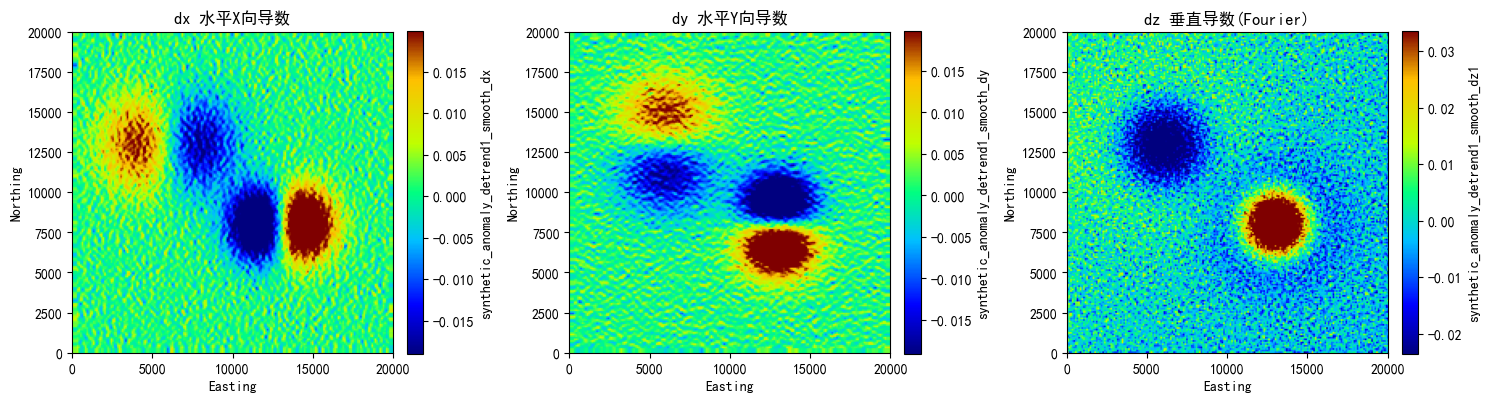

In [6]:
dx = clean.dx()
dy = clean.dy()
dz = clean.dz(method="fourier")
isvd_dz = clean.isvd(order=1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, g, t in zip(axes, [dx, dy, dz], ["dx 水平X向导数", "dy 水平Y向导数", "dz 垂直导数(Fourier)"]):
    g.show(ax=ax, hs=False, colorbar=True)
    ax.set_title(t)
plt.tight_layout()


## 5. 边界识别算子

- **HGM**（水平梯度模）：突出最陡梯度带
- **Tilt**（倾斜角）：弱异常也能显示
- **TG**（总梯度/解析信号）：峰值对应场源边界
- **TAHG**：对 HGM 再做一次 tilt，进一步锐化


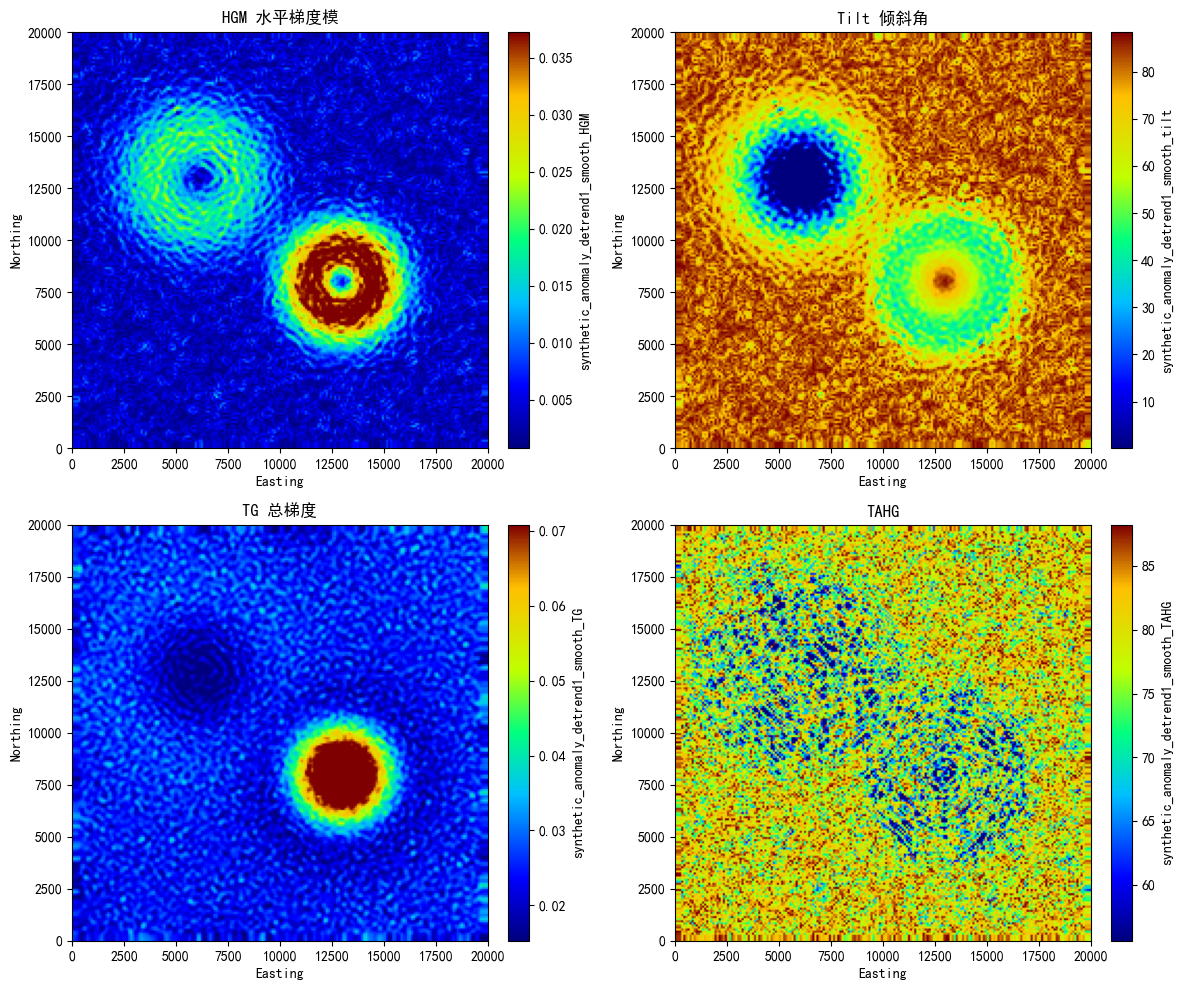

In [7]:
hgm = clean.hgm()
tilt = clean.tilt()
tg = clean.tg()
tahg = clean.tahg()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, g, t in zip(axes.ravel(), [hgm, tilt, tg, tahg],
                    ["HGM 水平梯度模", "Tilt 倾斜角", "TG 总梯度", "TAHG"]):
    g.show(ax=ax, hs=False, colorbar=True)
    ax.set_title(t)
plt.tight_layout()


## 6. 向上延拓与区域-局部分离

- `up(z=2000)`：向上延拓 2 km，压制浅部高频噪声，得到区域场
- `hp_filter_uc(z=5000)`：高通滤波 = 原始 − 向上延拓，分离浅部局部异常


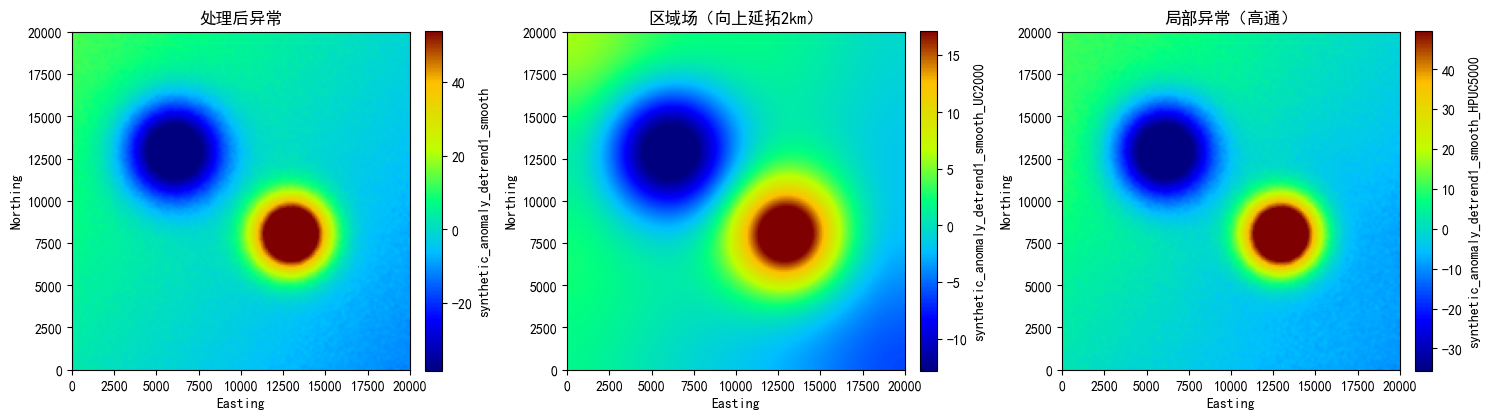

In [8]:
regional = clean.up(z=2000)
residual = clean.hp_filter_uc(z=5000)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, g, t in zip(axes, [clean, regional, residual],
                    ["处理后异常", "区域场（向上延拓2km）", "局部异常（高通）"]):
    g.show(ax=ax, hs=False, colorbar=True)
    ax.set_title(t)
plt.tight_layout()


## 7. 完整链式调用

所有方法都返回 `Grid`，可以一行串起整个流程：


已保存 tilt_result.tif


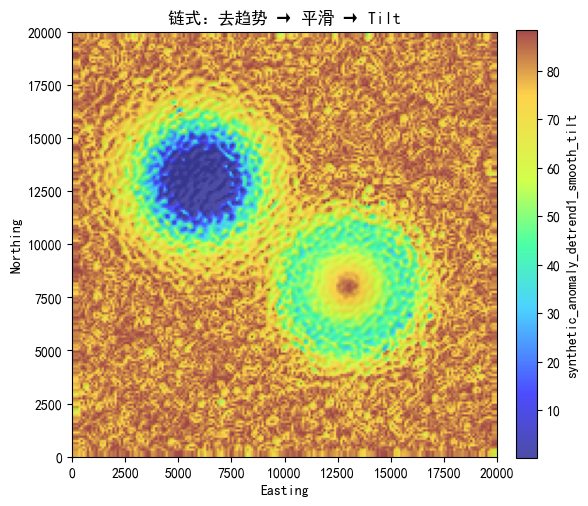

In [9]:
result = (
    grid
    .detrend(degree=1)
    .smooth(win=5)
    .tilt()
)
result.show(title="链式：去趋势 → 平滑 → Tilt", figsize=(6, 6))
result.save("tilt_result.tif")  # 写出 GeoTIFF（需要 rasterio）
print("已保存 tilt_result.tif")


## 备注

- 本示例使用合成数据，无需 rasterio/GDAL。
- 若要读取真实 GXF/GeoTIFF 文件，先 `pip install rasterio`，然后：
  ```python
  g = ip.open("data/brtpgrd.gxf")
  ```
- 所有变换算法见 `interpies_lite/transforms.py`，成图参数见 `interpies_lite/graphics.py`。
